# Quiz 3：泛化與可解釋性 / Generalization and XAI

**蘇芯儀 / Sharon0726**

In [1]:
# 子目標：定位作業目錄，讀取已完成的真實實驗結果。
from pathlib import Path
import csv, json
import numpy as np
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT / "results" / "metrics.json").exists():
    raise FileNotFoundError("請在 Week3 作業目錄開啟 Notebook。")
R = ROOT / "results"
metrics = json.loads((R / "metrics.json").read_text())
selected = json.loads((R / "selection.json").read_text())["selected"]
classes = json.loads((R / "classes.json").read_text())
def table(rows, columns):
    text = "| " + " | ".join(columns) + " |\n| " + " | ".join(["---"]*len(columns)) + " |\n"
    for row in rows:
        text += "| " + " | ".join(str(row[c]) for c in columns) + " |\n"
    display(Markdown(text))
def figure(name):
    display(Image(filename=str(R / "figures" / name)))


## Quiz 3：泛化與可解釋性（基礎 15＋進階 20 分）

### Data Augmentation 前後比較

在原始 32×32 RGB 影像上，先 reflection padding 4 pixels，再各自隨機選擇 32×32 crop，並以 p=0.5 水平翻轉。避免垂直翻轉、過強旋轉或遮蔽，以減少破壞自然物件語意；類別標籤不變。

每張訓練影像產生 **兩個固定且獨立的擴增視角**（seed=20260924、20260925），交替用於不同 epochs。每個 epoch 仍只有 45,000 筆，各原圖出現一次，沒有以資料量或步數倍增造成不公平比較。這是有限視角擴增，不是每個 epoch 重新抽樣無限視角。Plain 與 ResNet 使用相同視角；後者在擴增後才放大為 64×64 並快取特徵。

baseline／augmentation 固定同一 learning rate、初始化 seed、batch order、optimizer、weight decay、epochs、split 與評估流程；唯一的輸入差異是訓練時是否使用擴增。最佳 epoch 仍使用相同的 validation 選模規則，因此兩者最佳 epoch 可能不同。

| 模型 | Baseline Top-1 | Augmented Top-1 | 差異 | Top-5 baseline → aug | Macro-AUC baseline → aug |
| --- | --- | --- | --- | --- | --- |
| plain | 72.47% | 74.68% | +2.21 pp | 98.09% → 98.34% | 0.9607 → 0.9669 |
| resnet | 76.26% | 75.31% | -0.95 pp | 98.63% → 98.48% | 0.9709 → 0.9695 |

- **plain**：test Top-1 提高 2.21 個百分點；validation Top-1 由 72.58% 變成 75.24%。最終依 validation 選用 `plain_lr0.001_aug`。測試差異只用於事後報告，沒有回頭調整策略。
- **resnet**：test Top-1 降低 0.95 個百分點；validation Top-1 由 76.74% 變成 76.08%。最終依 validation 選用 `resnet_lr0.001_base`。測試差異只用於事後報告，沒有回頭調整策略。


擴增讓模型見到不同位置與左右方向，但也可能裁掉重要線索。尤其 frozen ResNet 不能更新 Backbone 以適應擴增，只能由 head 調整決策。效果取決於模型、增強強度與訓練預算，不能預設一定提升。

### 兩個訓練後 Kernel 的視覺化

取最終 Plain CNN 第一層的 **output kernel 0 與 1**，以固定索引選取，避免事後挑選好看的圖。每個 Kernel 實際為 3×3×3；圖中分別顯示 R／G／B 通道的帶正負權重，以及共用對稱尺度的 RGB 合成視圖。合成色彩是權重顯示方式，不是原始影像或 Feature Map。


為使解讀有數值依據，額外輸入 vertical／horizontal／diagonal edge 與 R／G／B 單色探針，量測不含 bias、ReLU 的 convolution 平均絕對響應。探針採正規化座標，作用是比較局部權重偏好，不是自然影像分類測試。

- **Kernel 0**：三種等振幅邊緣探針中，`vertical edge` 的平均絕對線性響應最大（0.9819）；三種單色探針中，`red field` 響應最大（0.4237）。這支持它對該類局部亮暗／通道組合較敏感的解讀，但不能直接命名為某種物件偵測器。
- **Kernel 1**：三種等振幅邊緣探針中，`diagonal edge` 的平均絕對線性響應最大（0.7174）；三種單色探針中，`green field` 響應最大（0.4183）。這支持它對該類局部亮暗／通道組合較敏感的解讀，但不能直接命名為某種物件偵測器。

從帶符號權重看，Kernel 0 的 R 通道多數為負值，左下角為正，呈現通道抑制與局部對比的混合；因此「red field 絕對響應大」不等於「正向偵測紅色」。Kernel 1 的 G 通道左欄多為負、右側偏正，具有左右亮暗對比的線索；合併三通道後，控制探針顯示它對斜向邊緣的反應更強。此解讀同時參考實際權重與探針，不單憑合成顏色命名功能。


小尺寸 Kernel 可能混合邊緣、顏色與紋理訊號；不能只憑彩色方格就斷言它已學到「貓耳」或「車輪」。後續層才會組合這些低階特徵。

### XAI：Grad-CAM 與模型關注區域

對最終 Plain CNN 的最後一層 convolution `features[6]`（8×8 feature maps）實作 [Grad-CAM](https://arxiv.org/abs/1610.02391)：以 **predicted class 的 logit** 對 feature maps 求梯度，取空間平均作為 channel weights，加權後套 ReLU，再 bilinear 放大至 32×32。每張熱圖除以自己的最大值；不同樣本的顏色強度不能直接作絕對比較。

固定選取測試索引中最先出現的兩個正確案例與兩個錯誤案例，各組要求真實類別不同；未依 confidence 或熱圖好看程度挑選。


- **Test #0，cat → cat（76.14%）**：主要熱區在影像中央偏右的貓身體附近，另有上緣小塊熱區；模型並非只關注左側的臉部。遮蔽高熱區後 cat 機率下降 0.5114，但遮蔽低熱區也下降 0.5633，說明熱圖只涵蓋部分有效線索。
- **Test #1，ship → ship（96.85%）**：最亮區域位於船隻上方的淺色背景，船體中央僅有次要熱區。遮蔽低熱區的機率降幅 0.9198，遠高於高熱區的 0.1527；因此這張 Grad-CAM 的空間排序並未忠實涵蓋所有重要證據，不能據此宣稱模型準確定位船體。
- **Test #5，frog → dog（66.30%）**：熱區集中在左側邊緣及右側局部，中央可見的青蛙輪廓反而不明顯。這與模型可能利用局部褐色紋理或背景線索的假設一致，但不足以證明誤判原因；高、低熱區遮蔽都明顯降低 dog 機率。
- **Test #24，dog → deer（93.89%）**：高熱度大範圍分布在上方與右側背景，中央較深的狗身體呈低熱度。模型即使信心很高仍然答錯。高熱區遮蔽只降低 0.0442，低熱區遮蔽反而提高約 0.0295；此結果提示背景捷徑與局部解釋侷限，不能把熱度直接當成可靠的物件證據。

四個案例中，前三個的低熱區遮蔽都比高熱區造成更大的機率下降。這是一項不支持「高熱度必然更重要」的實測結果；本作業保留這些案例，而沒有更換成較漂亮的熱圖。


為輔助檢查熱圖，分別將最高／最低熱度的 25% pixels 以 ImageNet channel means 取代，重新量測 predicted-class probability。Δp=原始機率−遮蔽後機率；正值代表遮蔽使該預測的支持下降，負值代表遮蔽反而提升。

| Test index | True → Predicted | Confidence | 遮蔽高熱區 Δp | 遮蔽低熱區 Δp |
| --- | --- | --- | --- | --- |
| 0 | cat → cat | 76.14% | +0.5114 | +0.5633 |
| 1 | ship → ship | 96.85% | +0.1527 | +0.9198 |
| 5 | frog → dog | 66.30% | +0.4243 | +0.4950 |
| 24 | dog → deer | 93.89% | +0.0442 | -0.0295 |

這是局部擾動診斷；分散像素遮蔽也可能產生 out-of-distribution 圖樣，不能視為物件區域的因果證明。Grad-CAM 的解析度只有 8×8，也不等同 segmentation mask。錯誤預測的熱圖解釋的是模型所預測的類別，並非保證指出真實物件。


| model | baseline_Top1 | aug_Top1 | delta_pp |
| --- | --- | --- | --- |
| plain | 72.47% | 74.68% | 2.21 |
| resnet | 76.26% | 75.31% | -0.95 |


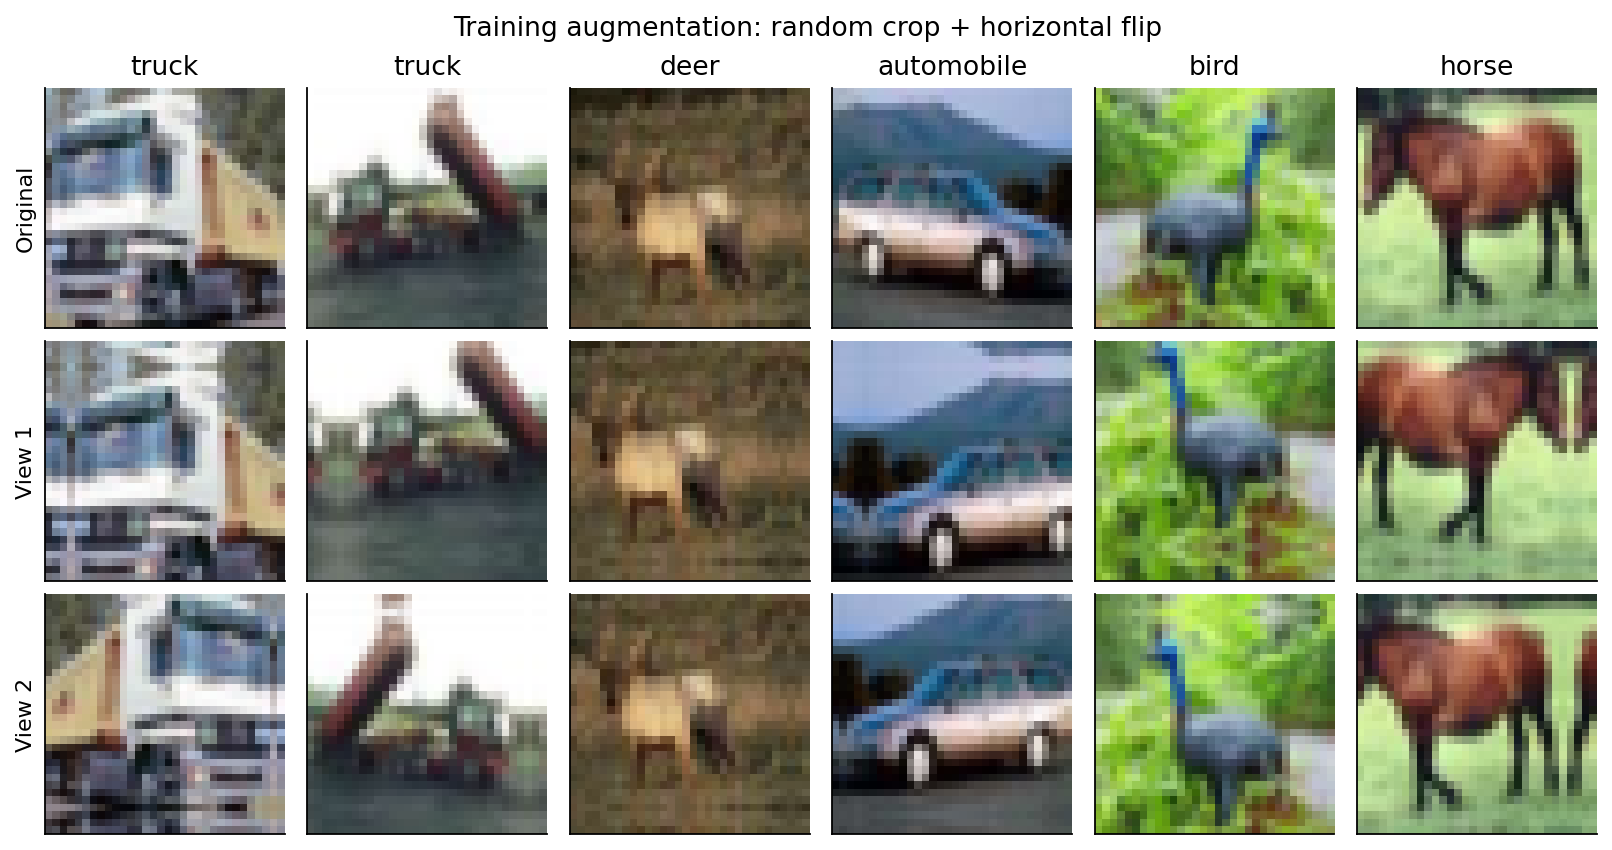

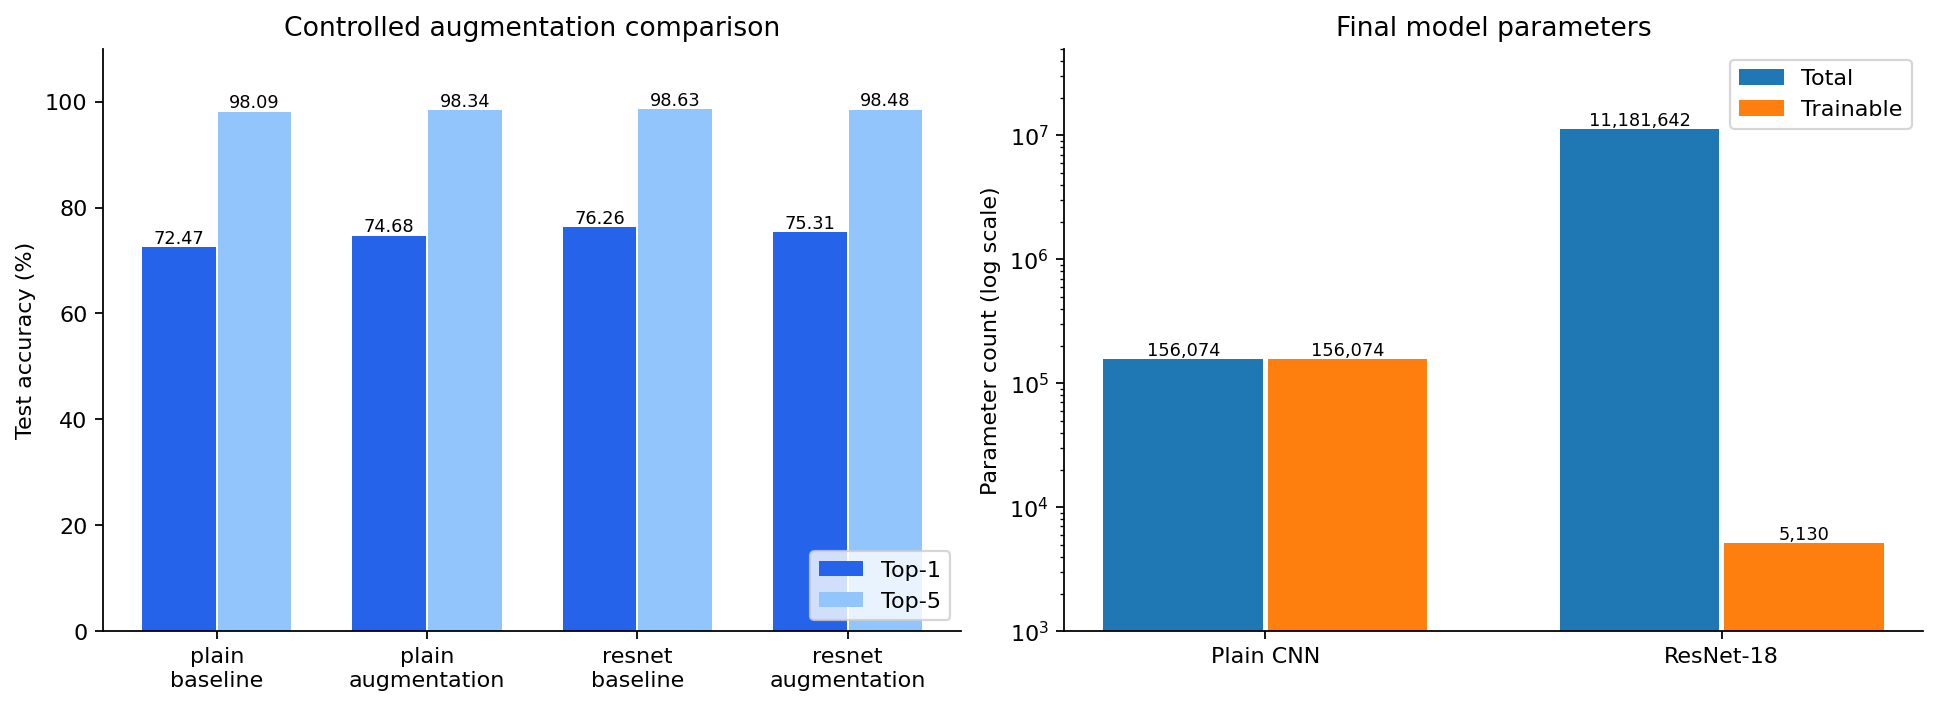

In [2]:
# 子目標：固定其他設定，重算資料擴增的實測差異。
rows = []
for family in ["plain", "resnet"]:
    base = next(r for r in metrics if r["run"] == selected[family]["baseline"])
    aug = next(r for r in metrics if r["run"] == selected[family]["augmented"])
    assert base["lr"] == aug["lr"] and base["epochs"] == aug["epochs"]
    rows.append({"model": family, "baseline_Top1": f"{base['test_top1']:.2%}",
                 "aug_Top1": f"{aug['test_top1']:.2%}",
                 "delta_pp": round(100*(aug["test_top1"]-base["test_top1"]), 2)})
table(rows, list(rows[0]))
figure("augmentation_examples.png")
figure("model_comparison.png")

Kernel tensor shape [output, input, height, width]: (2, 3, 3, 3)


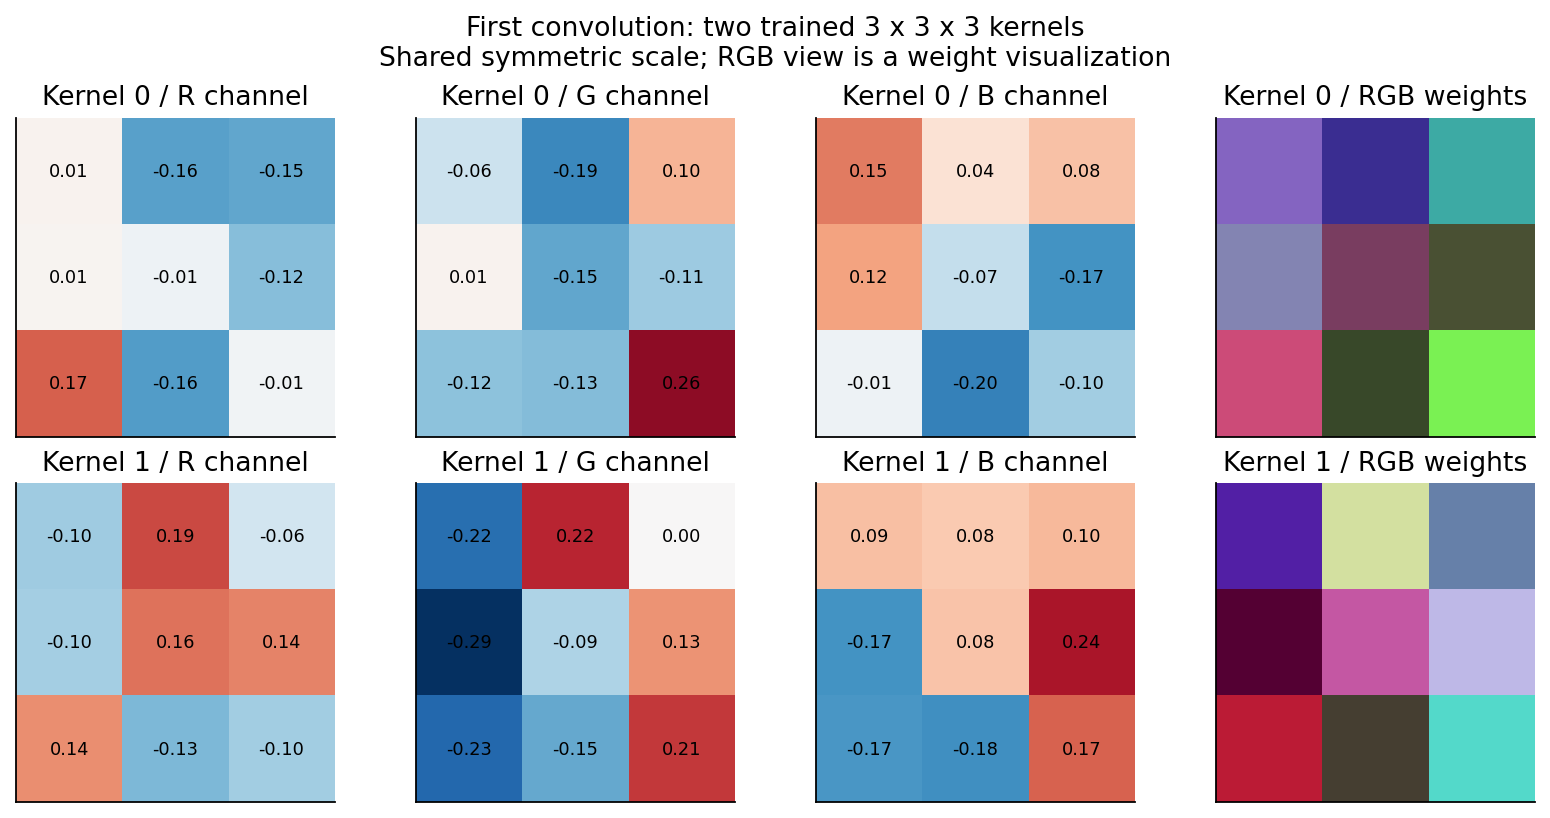

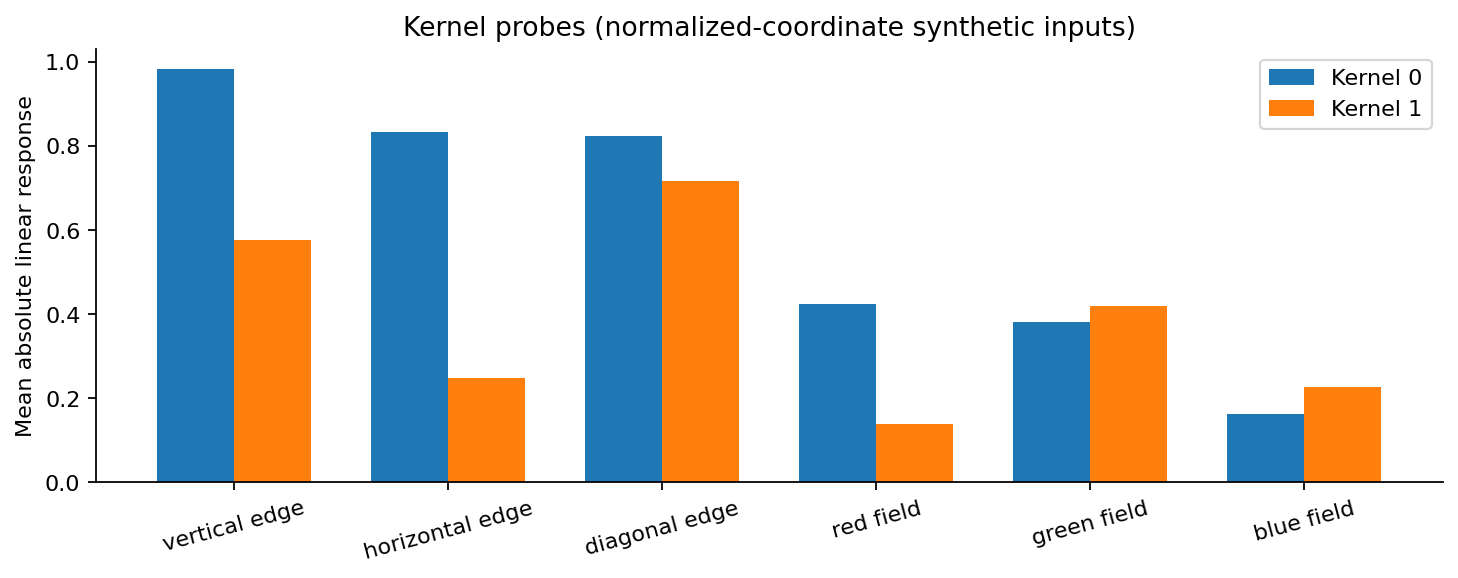

| kernel | vertical edge | horizontal edge | diagonal edge | red field | green field | blue field |
| --- | --- | --- | --- | --- | --- | --- |
| 0 | 0.9818910360336304 | 0.8329048156738281 | 0.8223851919174194 | 0.42371875047683716 | 0.3799426853656769 | 0.16200591623783112 |
| 1 | 0.5763401389122009 | 0.24717161059379578 | 0.71737140417099 | 0.13907907903194427 | 0.4183085262775421 | 0.22737663984298706 |


In [3]:
# 子目標：展示兩個實際訓練後的卷積權重與控制探針。
kernels = np.load(R / "kernel_weights.npy")
assert kernels.shape == (2, 3, 3, 3)
print("Kernel tensor shape [output, input, height, width]:", kernels.shape)
figure("two_kernels.png")
figure("kernel_probes.png")
with (R / "kernel_probe_responses.csv").open() as f:
    probes = list(csv.DictReader(f))
table(probes, list(probes[0]))

def grad_cam(model, x, target):
    activations = []
    handle = model.features[6].register_forward_hook(lambda module, inputs, output: activations.append(output))
    try:
        logits = model(x)
        gradients = torch.autograd.grad(logits[0, target], activations[0])[0]
        alpha = gradients.mean((2, 3), keepdim=True)
        heat = (alpha * activations[0]).sum(1, keepdim=True).relu()
        coarse = heat.detach().numpy()[0, 0]
        heat = F.interpolate(heat, (32, 32), mode="bilinear", align_corners=False)[0, 0].detach()
        heat = heat / heat.max().clamp_min(1e-12)
        return heat.numpy(), coarse
    finally:
        handle.remove()



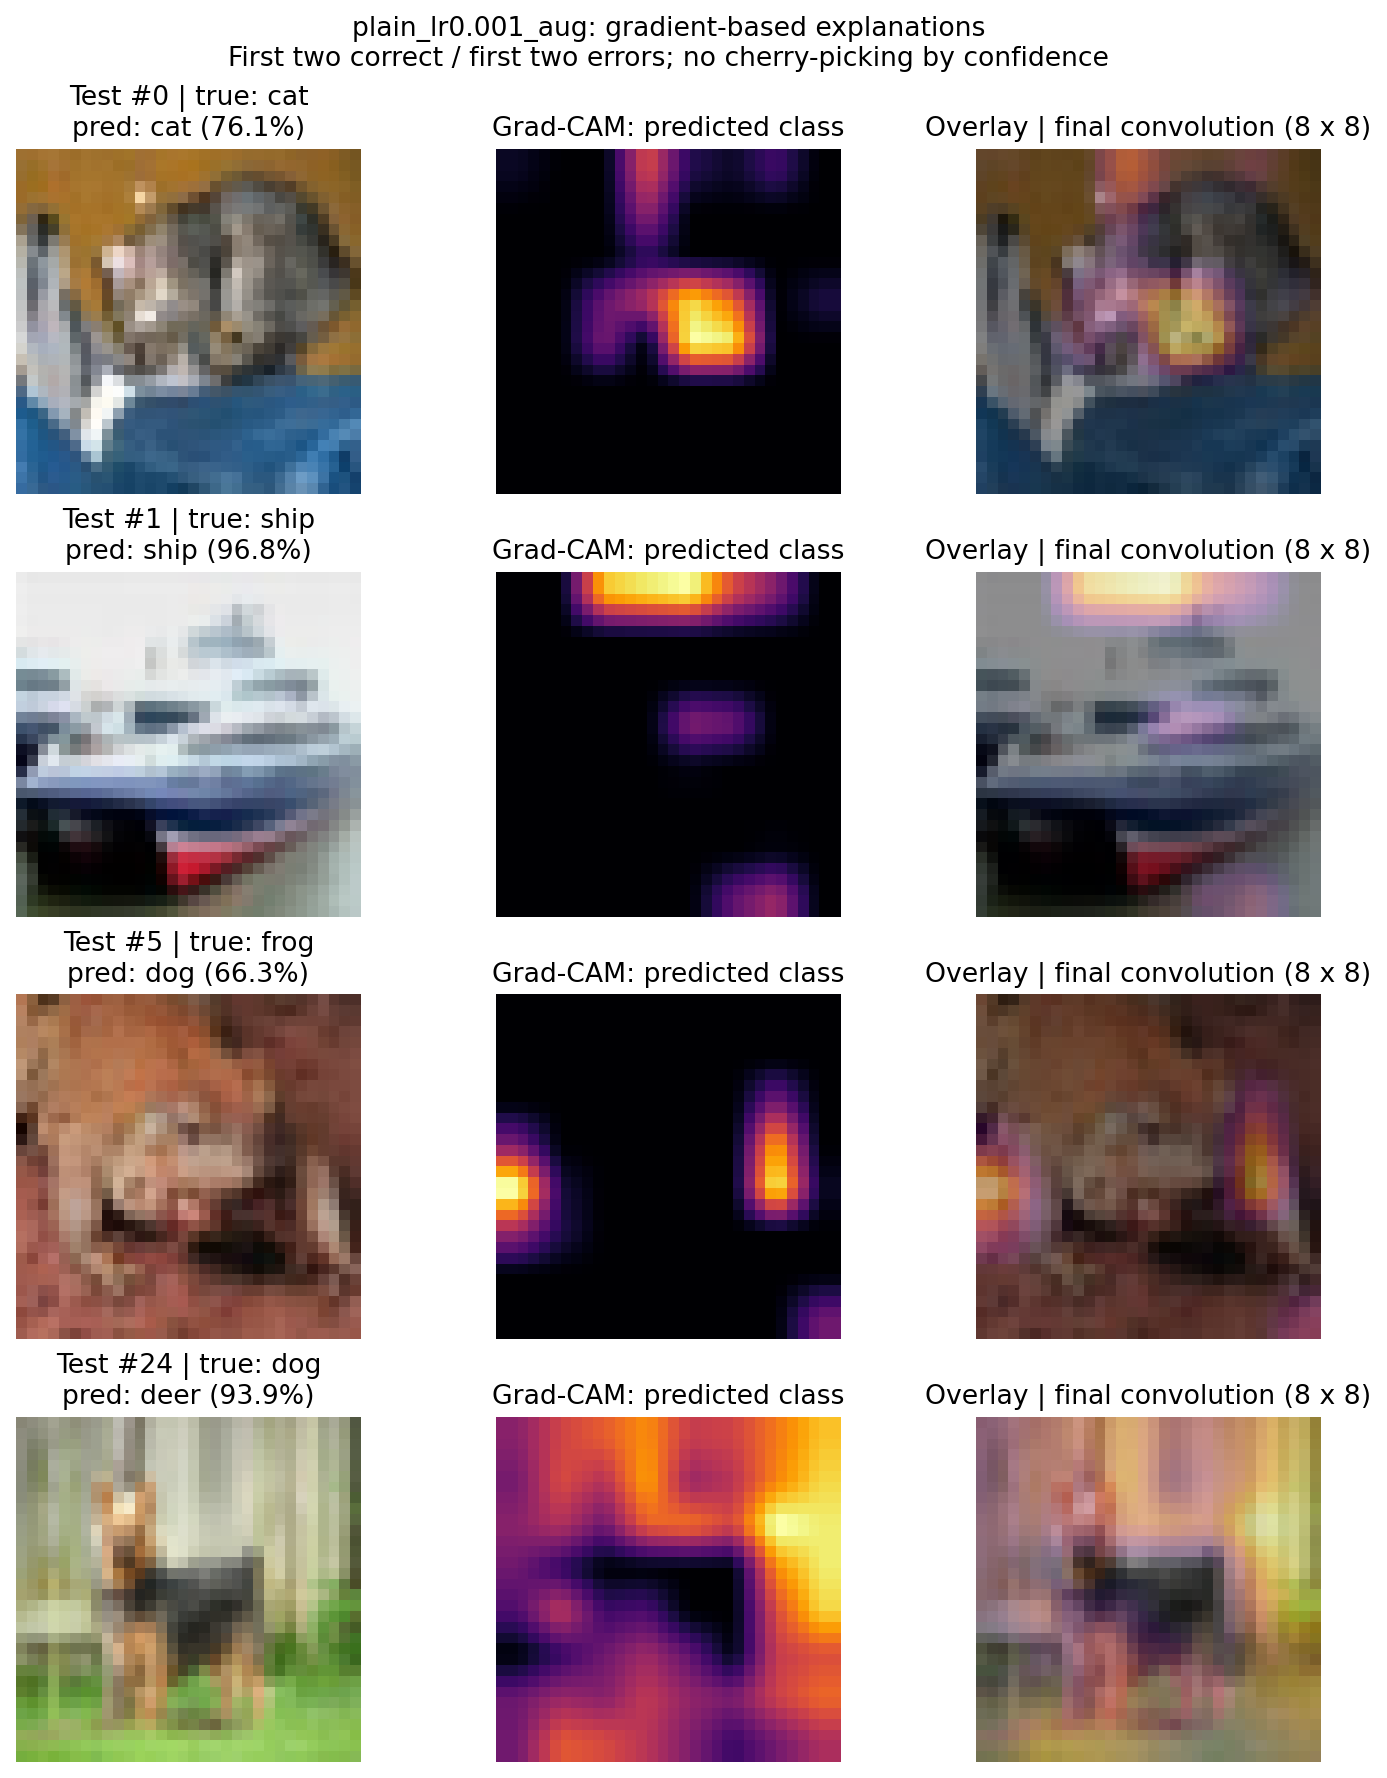

| test_index | true_class | target_predicted_class | probability | top_quarter_drop | bottom_quarter_drop |
| --- | --- | --- | --- | --- | --- |
| 0 | cat | cat | 0.7614498734474182 | 0.5114370584487915 | 0.5632610470056534 |
| 1 | ship | ship | 0.9684721231460571 | 0.15273255109786987 | 0.9197951853275299 |
| 5 | frog | dog | 0.6629893779754639 | 0.4243405908346176 | 0.4949678033590317 |
| 24 | dog | deer | 0.9389470219612122 | 0.04418468475341797 | -0.029497146606445312 |


{
  "status": "passed",
  "checks": [
    "Disjoint, class-balanced train/validation; official test indices; complete source accounting",
    "All six runs: 10,000 probability rows, normalized scores, recomputed Top-1/Top-5/Macro-AUC, CSV/NPZ equality",
    "Every checkpoint is the earliest maximum validation Top-1 epoch; complete training histories",
    "Validation-only family selection, controlled augmentation settings, correct total/trainable parameter counts",
    "Reloaded end-to-end models reproduce saved probabilities, including cached ResNet features",
    "Finite, nonzero Grad-CAM maps; two kernels exactly match the trained checkpoint"
  ],
  "experiments": 6,
  "prediction_rows": 60000
}


In [4]:
# 子目標：展示梯度計算方法、熱圖及遮蔽驗證。
import inspect
from analyze_results import grad_cam
print(inspect.getsource(grad_cam))
figure("gradcam_examples.png")
with (R / "xai_cases.csv").open() as f:
    cases = list(csv.DictReader(f))
table(cases, ["test_index", "true_class", "target_predicted_class", "probability", "top_quarter_drop", "bottom_quarter_drop"])
print((R / "verification.json").read_text(encoding="utf-8"))

### 解讀範圍

Grad-CAM 是特定模型、特定類別的局部梯度解釋。熱圖不等同物件分割，也不能證明模型理解語意；單一 seed 的擴增改善不能當成普遍結論。